# Business Insights & Recommendations

## 1. Tujuan Analisis

Tahap ini bertujuan untuk menginterpretasikan hasil Exploratory Data Analysis (EDA) pada dataset Dirty Cafe Sales. Hasil analisis digunakan untuk mengidentifikasi pola transaksi, produk yang berkontribusi terhadap penjualan, serta peluang perbaikan strategi bisnis kafe.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("../data/processed/cafe_sales_clean.csv")

df["Transaction Date"] = pd.to_datetime(
    df["Transaction Date"], errors="coerce"
)

print("Jumlah baris:", df.shape[0])
print("Jumlah kolom:", df.shape[1])

Jumlah baris: 10000
Jumlah kolom: 8


## 2. Temuan Utama

Berdasarkan hasil EDA, terdapat beberapa temuan awal:

1. **Produk paling sering muncul:** Juice dengan 1.171 transaksi yang memiliki informasi produk.
2. **Produk dengan total penjualan tertinggi:** Salad dengan total 17.320 satuan nilai pada kolom Total Spent.
3. **Metode pembayaran:** Digital Wallet paling banyak tercatat, yaitu 2.291 transaksi dengan metode pembayaran yang diketahui.
4. **Lokasi transaksi:** Takeaway tercatat sebanyak 3.022 transaksi, sedangkan In-store sebanyak 3.017 transaksi.
5. **Tren transaksi bulanan:** Oktober memiliki jumlah transaksi tertinggi, yaitu 838, sedangkan Februari terendah, yaitu 727.

Catatan: beberapa kolom masih memiliki data kosong. Oleh karena itu, temuan di atas menggambarkan data yang tersedia dan belum tentu mewakili seluruh transaksi secara lengkap.

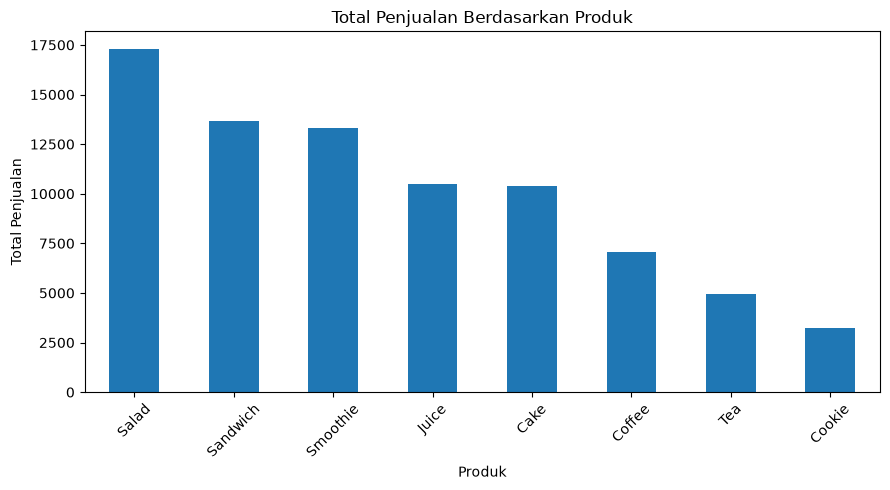

In [2]:
# Total penjualan berdasarkan produk
penjualan_produk = (
    df.dropna(subset=["Item", "Total Spent"])
      .groupby("Item")["Total Spent"]
      .sum()
      .sort_values(ascending=False)
)

plt.figure(figsize=(9, 5))
penjualan_produk.plot(kind="bar")
plt.title("Total Penjualan Berdasarkan Produk")
plt.xlabel("Produk")
plt.ylabel("Total Penjualan")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 3. Rekomendasi Bisnis

Berdasarkan temuan awal, rekomendasi yang dapat dipertimbangkan adalah:

1. **Evaluasi penjualan produk:** Kafe dapat mengevaluasi strategi promosi dan penyediaan stok untuk produk dengan total penjualan tinggi seperti Salad.
2. **Evaluasi produk populer:** Juice sering muncul dalam data transaksi sehingga dapat dipertimbangkan dalam strategi promosi, dengan tetap memperhatikan keuntungan dan biaya produk.
3. **Evaluasi metode pembayaran:** Kafe dapat mempertahankan kemudahan pembayaran digital sekaligus memastikan pilihan pembayaran lain tetap tersedia.
4. **Perencanaan operasional:** Kafe dapat mengevaluasi kebutuhan stok dan tenaga kerja berdasarkan perubahan jumlah transaksi bulanan.
5. **Perbaikan kualitas data:** Pencatatan metode pembayaran, lokasi transaksi, dan tanggal perlu ditingkatkan agar analisis bisnis berikutnya lebih akurat.

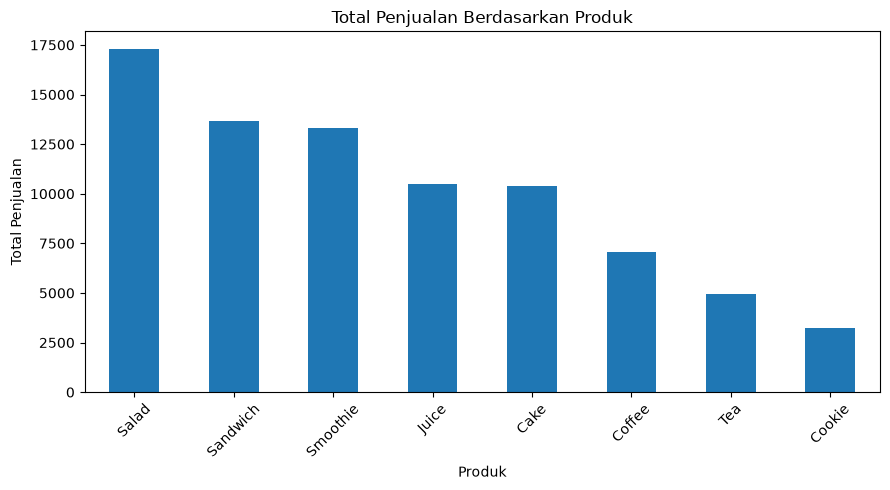

In [3]:
# Total penjualan berdasarkan produk
penjualan_produk = (
    df.dropna(subset=["Item", "Total Spent"])
      .groupby("Item")["Total Spent"]
      .sum()
      .sort_values(ascending=False)
)

plt.figure(figsize=(9, 5))
penjualan_produk.plot(kind="bar")

plt.title("Total Penjualan Berdasarkan Produk")
plt.xlabel("Produk")
plt.ylabel("Total Penjualan")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

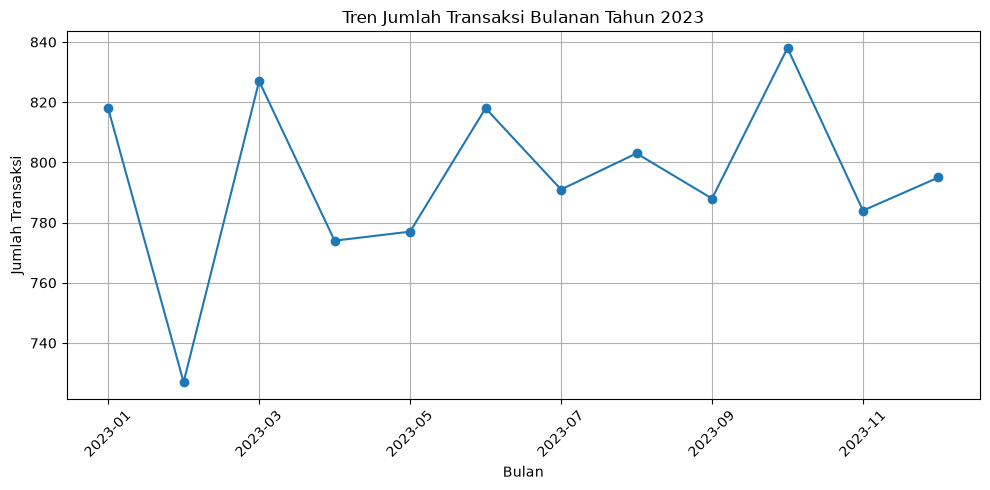

In [4]:
# Jumlah transaksi setiap bulan
transaksi_bulanan = (
    df.dropna(subset=["Transaction Date"])
      .groupby(df["Transaction Date"].dt.to_period("M"))
      .size()
)

transaksi_bulanan.index = transaksi_bulanan.index.astype(str)

plt.figure(figsize=(10, 5))
transaksi_bulanan.plot(kind="line", marker="o")

plt.title("Tren Jumlah Transaksi Bulanan Tahun 2023")
plt.xlabel("Bulan")
plt.ylabel("Jumlah Transaksi")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

## 3. Rekomendasi Bisnis

Berdasarkan hasil analisis, rekomendasi yang dapat dipertimbangkan adalah:

1. **Evaluasi penjualan produk:** Salad memiliki total penjualan tertinggi sehingga kafe dapat mengevaluasi ketersediaan stok dan strategi penjualannya.
2. **Promosi produk populer:** Juice merupakan produk yang paling sering muncul dalam data transaksi sehingga dapat dipertimbangkan untuk strategi promosi.
3. **Metode pembayaran:** Digital Wallet menjadi metode pembayaran yang paling banyak tercatat. Kafe dapat mempertahankan kemudahan pembayaran digital sambil menyediakan alternatif pembayaran lain.
4. **Perencanaan operasional:** Kafe dapat menggunakan pola transaksi bulanan sebagai salah satu pertimbangan dalam mengatur persediaan dan tenaga kerja.
5. **Peningkatan kualitas data:** Pencatatan metode pembayaran, lokasi, dan tanggal transaksi perlu ditingkatkan agar analisis berikutnya lebih akurat.

## 4. Kesimpulan

Analisis dataset Dirty Cafe Sales menunjukkan adanya perbedaan kontribusi penjualan antarproduk, variasi metode pembayaran, serta perubahan jumlah transaksi dari bulan ke bulan. Salad memiliki total penjualan tertinggi, sedangkan Juice paling sering muncul dalam transaksi yang memiliki informasi produk.

Hasil ini dapat menjadi dasar evaluasi operasional dan strategi penjualan kafe. Namun, interpretasi tetap perlu mempertimbangkan data yang kosong dan keterbatasan informasi pada dataset. Analisis ini menunjukkan pola data, bukan membuktikan penyebab perubahan penjualan.